# Activity 1: Introduction to Regression with Auto MPG

**Learning Objectives**

By the end of this activity, you should be able to:

- explain what a regression problem is;
- identify features and a target variable;
- describe the Auto MPG dataset;
- explain the meaning of MPG;
- use a scatter plot to investigate a relationship between two variables;
- calculate and interpret Pearson Correlation Coefficient (r);
- build a simple linear regression model;
- interpret a regression coefficient and intercept;
- make predictions using a regression model;
- understand the difference between training data and test data;
- evaluate a regression model using MAE, RMSE, and R²;
- explain the basic idea of multiple linear regression.

# Question 1: Identify the Machine-Learning Problem

1. Is this supervised or unsupervised learning?

This is supervised learning because the dataset contains a known target known as `mpg`.

2. Is it classification or regression?

It is regression because we are dealing with a numerical quantity.

3. What is the target?

`mpg` or miles per gallon.

4. Give two possible features.

weight, horsepower, displacement, cylinders.

# 1. Install the Required Libraries

In [1]:
!pip install -q ucimlrepo scikit-learn pandas matplotlib

## 1.1 Import the Libraries

The main libraries have different purposes.

**pandas** - Used for working with tables and datasets.

**matplotlib** - Used for visualizations.

**scikit-learn** - Used for machine-learning tasks such as:

- splitting data;
- creating models;
- training models;
- making predictions;
- evaluating models.

**ucimlrepo** - Used here to retrieve the Auto MPG dataset from UCI.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# 2. Load the Auto MPG Dataset

The UCI repository provides Auto MPG as dataset ID `9`.

In [5]:
auto_mpg = fetch_ucirepo(id=9)

X_full = auto_mpg.data.features
y_full = auto_mpg.data.targets

print("Features (X-axis):\n", X_full.head())
print("\nTargets (Y-axis):\n", y_full.head())

print("\nVariables:\n", auto_mpg.variables)

Features (X-axis):
    displacement  cylinders  horsepower  ...  acceleration  model_year  origin
0         307.0          8       130.0  ...          12.0          70       1
1         350.0          8       165.0  ...          11.5          70       1
2         318.0          8       150.0  ...          11.0          70       1
3         304.0          8       150.0  ...          12.0          70       1
4         302.0          8       140.0  ...          10.5          70       1

[5 rows x 7 columns]

Targets (Y-axis):
     mpg
0  18.0
1  15.0
2  18.0
3  16.0
4  17.0

Variables:
            name     role         type  ... description units missing_values
0  displacement  Feature   Continuous  ...        None  None             no
1           mpg   Target   Continuous  ...        None  None             no
2     cylinders  Feature      Integer  ...        None  None             no
3    horsepower  Feature   Continuous  ...        None  None            yes
4        weight  Feature   Co

## Question 2: Explore the Dataset

In [7]:
display(X_full.info())

X_full.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   displacement  398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   horsepower    392 non-null    float64
 3   weight        398 non-null    int64  
 4   acceleration  398 non-null    float64
 5   model_year    398 non-null    int64  
 6   origin        398 non-null    int64  
dtypes: float64(3), int64(4)
memory usage: 21.9 KB


None

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin
count,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398.000000
mean,193.425879,5.454774,104.469388,2970.424623,15.568090,76.010050,1.572864
std,104.269838,1.701004,38.491160,846.841774,2.757689,3.697627,0.802055
min,68.000000,3.000000,46.000000,1613.000000,8.000000,70.000000,1.000000
25%,104.250000,4.000000,75.000000,2223.750000,13.825000,73.000000,1.000000
50%,148.500000,4.000000,93.500000,2803.500000,15.500000,76.000000,1.000000
75%,262.000000,8.000000,126.000000,3608.000000,17.175000,79.000000,2.000000
max,455.000000,8.000000,230.000000,5140.000000,24.800000,82.000000,3.000000


### Questions

*1. Approximately how many observations are there?*

- The dataset contains 398 observations in total.

*2. Which variable is the target?*

- `mpg`

*3. Which variables are numerical?*

- All the variables in the dataset are numerical.

*4. Does any feature contain missing values?*

- `horsepower` feature contains 6 missing values.

*5. Which feature would be a reasonable candidate for predicting mpg?*

- For the introductory activity, `weight` is a useful feature because it is numerical and has a natural relationship with fuel efficiency.


# 3. Select a Feature and Target

For the first regression example, we will use:

`weight → mpg`

That means:

```text
X = weight
y = mpg
```

In [9]:
X = X_full[["weight"]]    # Double brackets produces a DataFrame containing the feature
y = y_full["mpg"]

## Question 3: Why Use `weight`?

*Do you expect heavier cars to have higher or lower MPG?*

- Heavier cars will have lower MPG because of the following reasons:

  - Inertia and acceleration ($F=ma$)
  - Rolling resistance
  - Engine workload

This means that when running a linear regression or calculating a correlation coefficient (e.g., Pearson's $r$) between weight and MPG, we should expect to see a negative slope / negative correlation coefficient.

# 4. Visualise the Relationship

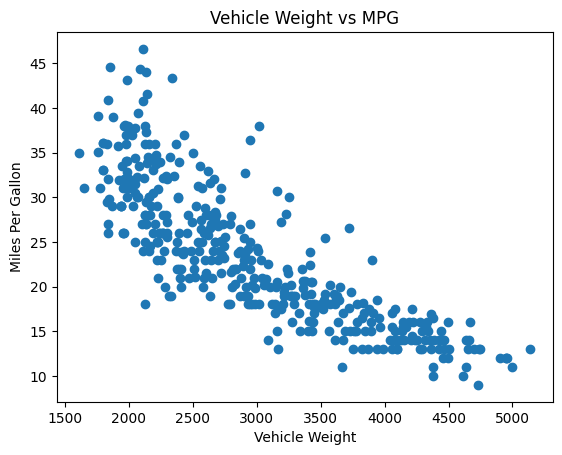

In [10]:
plt.scatter(X["weight"], y)

plt.xlabel("Vehicle Weight")
plt.ylabel("Miles Per Gallon")
plt.title("Vehicle Weight vs MPG")

plt.show()

## Question 4: Read the Scatter Plot

*1. Does the relationship appear positive or negative?*

- The relationship appears negative.

*2. Does it appear approximately linear?*

- It appears slightly curved, but approximately linear.

*3. Are all points exactly on one line?*

- No, the points are scattered slightly.

*4. Why might there be variation around the general trend?*

- While weight is one of the strongest predictors of fuel economy, vehicles of similar weights often have very different MPG ratings. This scatter around the main trend line occurs because several other mechanical, aerodynamic, and operational factors influence fuel consumption.

# 5. Pearson Correlation

The scatter plot gives us a visual impression.

**Pearson Correlation Coefficient** gives us a numerical summary of the strength and direction of a linear relationship.

It is represented by $r$.

and its possible values are $-1 ≤ r ≤ 1$.

A positive value means a *positive linear relationship*.

A negative value means a *negative linear relationship*.

A value near zero means *little or no linear association*.

## 5.1 Calculate the Correlation

In [12]:
correlation = X["weight"].corr(y)

print("Pearson correlation:", correlation)

Pearson correlation: -0.8317409332443352


### Question 5: Interpret Pearson $r$

Suppose the correlation is:
```
r = -0.83
```

Answer:

*1. What does the negative sign mean?*

- Negative sign represents negative linear relationship, meaning that as the weight increases, the mpg decreases.

*2. What does the magnitude tell you?*

- The magnitude of 0.83 indicates a strong linear association.

*3. Does `r = -0.83` prove that weight causes MPG to decrease?*

- No. $r$ only measures how two variables move together statistically, it does not reveal why they move together.

*4. Does it mean that every heavy car has lower MPG than every
light car?*

- No. Correlation describes the overall pattern. Individual observations can still differ substantially.

# 6. A Limitation of Pearson Correlation

While the Pearson correlation coefficient ($r$) is a powerful tool for measuring relationships between variables, it comes with several critical limitations that can lead to misleading conclusions if ignored:

**1. Assumes Only Linear Relationships**

Pearson correlation strictly measures linear patterns (straight-line trends). It is completely blind to non-linear relationships (such as U-shaped, exponential, or parabolic curves).
- The Risk: Two variables could have a perfect curved relationship (e.g., $y = x^2$), but their Pearson correlation might be near 0, falsely suggesting no relationship exists.

**2. Highly Sensitive to Outliers**

A single extreme outlier can drastically inflate or deflate the value of $r$.
- The Risk: Adding just one data point far away from the rest of the cluster can turn a strong positive correlation into a weak one, or make completely unrelated data appear strongly correlated.

**3. Does Not Imply Causation**

As discussed earlier, $r$ only measures association, not cause-and-effect. A high correlation might be driven by a confounding third variable or sheer coincidence (spurious correlation).

## Question 6: Pearson Limitation

Consider:
```
x = [-3, -2, -1, 0, 1, 2, 3]

y = [9, 4, 1, 0, 1, 4, 9]
```

Answer:

*1. Is there a relationship?*

- Yes, there is a perfect mathematical relationship given by $y=x^2$.

*2. Is it linear?*

- No, the relationship is quadratic/ not linear.

*3. Would Pearson correlation necessarily identify it as a strong relationship?*

- No. The Pearson correlation coefficient($r$) would evaluate to 0, indicating no relationship at all.

*4. Why?*

- Pearson correlation strictly measures the strength and direction of a linear (straight-line) relationship. Because the data is perfectly symmetrical around $x = 0$, the negative values on the left cancel out the positive values on the right, resulting in a slope of zero ($r = 0$). This highlights a primary limitation of Pearson correlation: it is blind to non-linear patterns.

# 7. From Correlation to Regression

Correlation answers a question such as:

*How strongly are weight and MPG linearly associated?*

Regression asks a different question:

*Can we use weight to predict MPG?*

A simple linear regression model can be written as:

$
\hat{y} = b_0 + b_1x$

For our example:

$\widehat{MPG}=b_0 + b_1(Weight)$

where:

* $b_0$ is the intercept;
* $b_1$ is the coefficient for weight.

The model learns these values from the data.

# 8. Create the Linear Regression Model

In [13]:
model = LinearRegression()

## 8.1 Train the Model

In [14]:
model.fit(X, y)

LinearRegression()

## 8.2 Examine the Model

The model examines:

```
X = vehicle weight
y = MPG
```

In [15]:
print("Intercept;", model.intercept_)
print("Coefficient:", model.coef_[0])

Intercept; 46.31736442026563
Coefficient: -0.007676610063926465


### Question 7: Interpret the Coefficient

Suppose the coefficient is negative.

*1. What does the negative sign mean?*

- The negative sign indicates an inverse relationship between the feature (predictor) and the target variable. It means that, holding all other features constant, as the feature value increases, the predicted target value decreases.

*2. What does the magnitude of the coefficient mean?*

- The magnitude (absolute value) represents the size of the expected change in the target variable for every one-unit increase in that feature. A larger magnitude means the feature has a larger per-unit impact on the prediction.

*3. Why should the coefficient be interpreted in terms of the units of the feature?*

- Because the coefficient directly scales the raw feature values. A raw coefficient of $-50$ for a feature measured in tons represents a change of $-50$ target units per ton, whereas the same feature measured in grams would yield a tiny coefficient of $-0.00005$ per gram. Without accounting for the feature's measurement units, we cannot evaluate whether a coefficient is practically large or small, nor can we directly compare unstandardized coefficients across different features.

*4. Does a negative coefficient mean the model is wrong?*

- No. A negative coefficient simply reflects that higher values of that feature predict lower values of the target, which is often logically expected depending on the domain (e.g., higher vehicle weight leading to lower MPG, higher house age leading to lower price, or higher price leading to lower demand). A negative coefficient only suggests an issue if domain knowledge dictating a positive relationship contradicts what the model learned, which usually signals problems like multicollinearity or omitted variable bias.


### Understanding the Intercept

The intercept is: $b_0$

It represents the model's predicted target when all features are zero.

In our simple model:

$\widehat{MPG} = b_0 + b_1(Weight)$

the intercept is the predicted MPG when:

$Weight = 0$

However, a vehicle with zero weight is not realistic.

Therefore, the intercept may be mathematically useful without having a meaningful real-world interpretation.

This is an important distinction:

```text
A model parameter can be mathematically necessary even when its value does not correspond to a realistic observation.
```


# 9. Draw the Regression Line

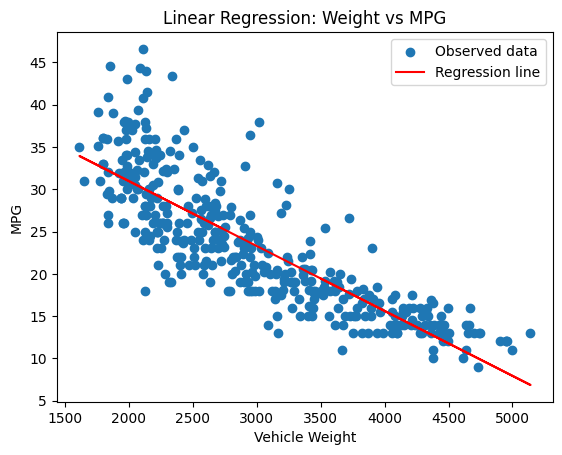

In [19]:
predictions = model.predict(X)

plt.scatter(X["weight"], y, label="Observed data")
plt.plot(X["weight"], predictions, label="Regression line", color="red")

plt.xlabel("Vehicle Weight")
plt.ylabel("MPG")
plt.title("Linear Regression: Weight vs MPG")

plt.legend()
plt.show()

### Question 8: Understand the Regression Line

Look at the plot.

*1. What do the individual points represent?*

- Each point in the plot represent an individual car in the dataset.

*2. What does the line represent?*

- The linear line represents the MPG predicted by the linear regression model for different vehicle weights.

*3. Why does the line not pass through every point?*

- Because vehicle weight is not the only factor that affects fuel efficiency.

*4. Why can the line still be useful even though it does not perfectly describe every car?*

- The regression line summarizes the overall relationship and can be used to make predictions for new observations.


# 10. Make a Prediction for a New Car

In [21]:
# Suppose we want to estimate MPG for a car weighing 3000
new_car = [[3000]]

prediction = model.predict(new_car)

print("Predicted MPG:", prediction[0])

Predicted MPG: 23.287534228486237


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


## 10.1 Convert the Prediction to $km/L$

The model predicts MPG because the target is `mpg`.

For European interpretation, we can convert the predicted value.

Conversion formula: $km/L ≈ MPG × 0.425$

In [22]:
predicted_mpg = prediction[0]

predicted_km_per_liter = predicted_mpg * 0.425

print("Predicted MPG:", predicted_mpg)
print("Approximate km/L:", predicted_km_per_liter)

Predicted MPG: 23.287534228486237
Approximate km/L: 9.897202047106651


### Question 9: Prediction

Suppose the model predicts 30 MPG.

*1. What does this prediction mean?*

- The model estimates that a car with the given weight has fuel efficiency of approximately 30 miles per US gallon.

*2. Approximately how many km/L is this?*

- $30 * 0.425 ≈ 12.75 km/L$

```
A prediction of 30 MPG means the car is expected to travel approximately 12.8 km per liter of fuel.
```

*3. Does this mean that every 3000-unit-weight car gets exactly 30 MPG?*

- No. The model provides an estimate based on the learned relationship.

*4. Is the prediction guaranteed to be correct?*

- No. A machine learning prediction is a statistical estimate (the average expected value) rather than a guaranteed real-world outcome.


# 11. Why Do We Need Training and Test Data?

So far, we trained the model using all available observations.

That is useful for demonstrating how regression works, but it creates a problem if we want to evaluate the model.

The model has already seen the data.

We therefore split the data into two parts:

                     Dataset
                        |
              --------------------
              |                  |
          Training             Test
             80%               20%
              |                  |
          Learn model       Evaluate model
The purpose of the test set is to estimate how well the trained model works on unseen observations.

## 11.1 Create the Train/Test Split

In [27]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Number of training set:", len(X_train))
print("Number of test set:", len(X_test))


Number of training set: 318
Number of test set: 80


### Question 10: Understand the Split

*1. What percentage of the observations is approximately used for testing?*

- 20%

*2. Which data should be used to train the model?*

- `X_train` and `y_train`.

*3. Which data should be used for final evaluation?*

- `X_test` and `y_test`.

*4. Why should the test data not be used for training?*

- The test data should represent unseen observations. If it is used during training, it is no longer an independent test of generalization.

*5. What is the purpose of random_state=42?*

- `random_state=42` makes the randomized split reproducible.


# 12. Train a Model Using Only the Training Data

In [28]:
model = LinearRegression()

model.fit(X_train, y_train)

LinearRegression()

## 12.1 Predict the Test Data

In [29]:
y_pred = model.predict(X_test)

## 12.2 Evaluate the Model with MAE

Mean Absolute Error is:

$$MAE=\frac{1}{n}\sum|y_i-\hat{y}_i|$$

It tells us the average absolute distance between the predicted values and the actual values.

In [30]:
mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error:", mae)

Mean Absolute Error: 3.1177861992064573


## 12.3 Evaluate with RMSE

Root Mean Square Error is:

$$RMSE = \sqrt{\frac{1}{n}\sum(y_i\hat{y}_i)^2}$$

It gives larger errors more influence because the errors are squared before averaging.

In [31]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Root Mean Square Error:", rmse)

Root Mean Square Error: 3.8593860994510765


## 12.4 Evaluate with $R^2$

$R^2$ provides another perspective on model performance.

$R^2$ can be interpreted as a measure of how much variation in the target is explained by the model relative to the reference baseline represented by the metric.

It is important not to interpret R² as "accuracy".

Regression does not use classification accuracy.

In [32]:
r2 = r2_score(y_test, y_pred)

print("R²:", r2)

R²: 0.722971057303075


### Question 11: Interpret the Metrics

Suppose the model produces:
```
MAE  = 3.12
RMSE = 3.86
R²   = 0.72
```

*1. What does MAE tell us?*

- MAE tells us that on average, the model's predictions are off by about 3.12 MPG (or roughly 1.33 km/L).

  If the model predicts a car gets 30 MPG, we can expect the actual value to typically fall around $30 \pm 3.12$ MPG. MAE treats all errors equally regardless of size.

*2. What does RMSE tell us?*

- RMSE tell us that the average size of prediction errors, with heavier penalties applied to larger mistakes, is about 3.86 MPG.

  Because RMSE squares errors before averaging them, larger blunders weigh more heavily on the score. Since the RMSE (3.86) is noticeably higher than MAE (3.12), it indicates that the model has a few unusually large prediction errors (outliers) pulling the metric up.

*3. Why is RMSE greater than MAE in this example?*

- RMSE is often larger than MAE because squaring the errors gives more weight to large errors.

*4. What does R² tell us?*

- The model explains 72.2% of the total variance in vehicle MPG.

  Vehicle weight (and any other features in the model) accounts for roughly 72% of why cars have different MPG values. The remaining ~28% of the variation is driven by factors not included in the model (like aerodynamics, driver habits, or engine efficiency).

*5. Why should we not call R² "72% accuracy"?*

- Accuracy is a classification metric. R² is a regression metric and does not mean that 72% of predictions are "correct."


# 13. Actual vs Predicted Values

A model that predicts perfectly would have:

$Predicted = Actual$ for every observation.

The points would therefore lie along a diagonal line.

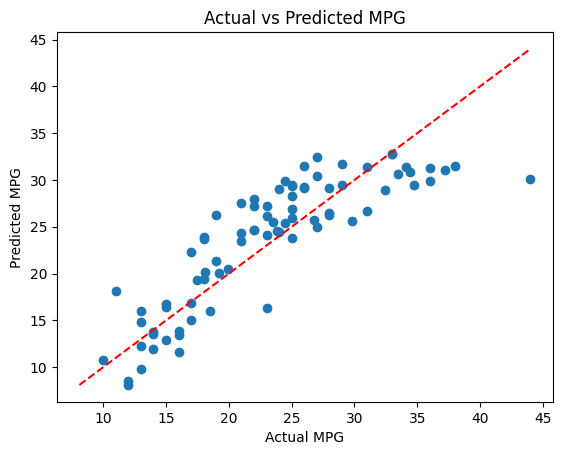

In [37]:
plt.scatter(y_test, y_pred)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--", color="red"
)

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Actual vs Predicted MPG")

plt.show()

### Question 12: Interpret the Prediction Plot

*1. What would a point exactly on the diagonal mean?*

- A point on the diagonal means the prediction equals the actual value.

*2. What does a point far from the diagonal mean?*

- A point far from the diagonal represents a larger prediction error.

*3. Would you expect all points to lie exactly on the diagonal?*

- No. Real-world predictions are rarely perfect.

*4. What does a cluster of points around the diagonal suggest?*

- A cluster of points close to the diagonal suggests that the predictions are generally close to the actual values.


# 14. Multiple Linear Regression

So far, the model has used one feature:

```text
weight
```

This is called **simple linear regression**.

However, real-world problems usually involve more than one feature.

For example, car fuel efficiency may depend on:

```text
weight
displacement
cylinders
horsepower
model_year
```

We can therefore use several features.

A multiple linear regression model can be written as:

$\hat{y}=b_0+b_1x_1+b_2x_2+b_3x_3+\cdots$

For example:

$\widehat{MPG}=b_0+b_1(Weight)+b_2(Displacement)+b_3(Cylinders)$


## 14.2 Select Multiple Features

In [38]:
X = X_full[["cylinders", "displacement", "weight"]]

y = y_full["mpg"]

## 14.3 Split the Multiple-Feature Data

In [39]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 14.4 Train Multiple Linear Regression

In [40]:
model = LinearRegression()

model.fit(X_train, y_train)

LinearRegression()

In [41]:
# Predict the model
y_pred = model.predict(X_test)

In [42]:
# Evaluate
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 3.1092532313465484
RMSE: 3.8661967069009027
R²: 0.7219924560018649


## 14.5 Examine the Multiple Regression Coefficients

In [43]:
print("Intercept:", model.intercept_)

for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", coefficient)

Intercept: 44.31685291951133
cylinders : -0.10181468483226533
displacement : -0.016942167127717435
weight : -0.005693627208100814


## 14.6. Important Idea: Interpreting Multiple Regression Coefficients

Suppose a coefficient for `weight` is negative.

A simplified interpretation is:
```
Holding the other model features constant, an increase in vehicle weight is associated with a decrease in predicted MPG.
```

The phrase:
```
holding the other features constant
```

is important.

In multiple regression, each coefficient represents the feature's contribution while accounting for the other features included in the model.

This is different from simply looking at the correlation between one feature and the target.

###  Question 13: Simple vs Multiple Linear Regression

Complete the following table:


| Model |	Number of Features |	Example |
|--------|-----------|--------|
|Simple Linear Regression	| 1 |	weight |
|Multiple Linear Regression|	2 or more | weight, cylinders, displacement |

Then answer:

*1. Why might multiple regression perform better than simple regression?*

- Multiple regression can use information from several characteristics of the car.

*2. Does adding more features always improve the model?*

- No. Adding more features can be irrelevant, noisy, redundant, or introduce other modeling problems.

*3. Why might some features be unhelpful?*

- Some features may contain little useful information for the target or may overlap strongly with other features.

# 15 Compare the One-Feature and Multiple-Feature Models

In [45]:
# Simple regression
X_simple = X_full[["weight"]]
y_simple = y_full["mpg"]

X_train_simple, X_test_simple, y_train_simple, y_test_simple = train_test_split(
    X_simple,
    y_simple,
    test_size=0.2,
    random_state=42
)

simple_model = LinearRegression()
simple_model.fit(X_train_simple, y_train_simple)

y_pred_simple = simple_model.predict(X_test_simple)

mae_simple = mean_absolute_error(y_test_simple, y_pred_simple)

rmse_simple = np.sqrt(
    mean_squared_error(y_test_simple, y_pred_simple)
)

r2_simple = r2_score(y_test_simple, y_pred_simple)

print("Simple Regression")
print("MAE:", mae_simple)
print("RMSE:", rmse_simple)
print("R²:", r2_simple)

Simple Regression
MAE: 3.1177861992064573
RMSE: 3.8593860994510765
R²: 0.722971057303075


In [46]:
X_multiple = X_full[
    [
        "cylinders",
        "displacement",
        "weight"
    ]
]

y_multiple = y_full["mpg"]

X_train_multiple, X_test_multiple, y_train_multiple, y_test_multiple = train_test_split(
    X_multiple,
    y_multiple,
    test_size=0.2,
    random_state=42
)

multiple_model = LinearRegression()

multiple_model.fit(
    X_train_multiple,
    y_train_multiple
)

y_pred_multiple = multiple_model.predict(X_test_multiple)

mae_multiple = mean_absolute_error(
    y_test_multiple,
    y_pred_multiple
)

rmse_multiple = np.sqrt(
    mean_squared_error(
        y_test_multiple,
        y_pred_multiple
    )
)

r2_multiple = r2_score(
    y_test_multiple,
    y_pred_multiple
)

print("Multiple Regression")
print("MAE:", mae_multiple)
print("RMSE:", rmse_multiple)
print("R²:", r2_multiple)

Multiple Regression
MAE: 3.1092532313465484
RMSE: 3.8661967069009027
R²: 0.7219924560018649


In [47]:
results = pd.DataFrame({
    "Model": [
        "Simple Linear Regression",
        "Multiple Linear Regression"
    ],
    "MAE": [
        mae_simple,
        mae
    ],
    "RMSE": [
        rmse_simple,
        rmse
    ],
    "R2": [
        r2_simple,
        r2
    ]
})

results

,Model,MAE,RMSE,R2
0,Simple Linear Regression,3.117786,3.859386,0.722971
1,Multiple Linear Regression,3.109253,3.866197,0.721992


### Question 14: Compare the Models

Use the results table.

1. Which model has the lower MAE?

- Multiple Linear Regression has slightly lower MAE.

2. Which model has the lower RMSE?

- Simple Linear Regression has slightly lower RMSE.

3. Which model has the higher R²?

- Simple Linear Regression.

4. Does the multiple-feature model perform better?

- Not really.

5. Is a model automatically better simply because it has more features?

- No. Adding features does not automatically guarantee better performance on unseen data.


# 16. A First Look at Overfitting and Underfitting

A model should not simply memorize the training observations.

The goal is to perform well on data it has not seen.

This gives us two important concepts.

**Underfitting**

The model is too simple to capture important patterns.

Typical pattern:
```
Training error: high
Test error:     high
```


**Overfitting**

The model fits the training data extremely well but performs poorly on unseen data.

Typical pattern:
```
Training error: very low
Test error:     much higher
```

# 15.1 Compare Training and Test Performance

In [48]:
train_predictions = multiple_model.predict(X_train_multiple)

test_predictions = multiple_model.predict(X_test_multiple)

In [49]:
train_rmse = np.sqrt(
    mean_squared_error(
        y_train_multiple,
        train_predictions
    )
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_test_multiple,
        test_predictions
    )
)

print("Training RMSE:", train_rmse)
print("Test RMSE:", test_rmse)

Training RMSE: 4.392137000192713
Test RMSE: 3.8661967069009027


### Question 15: Interpret Training vs Test Error

Suppose a model produces:
```
Training RMSE = 2.0
Test RMSE     = 8.0
```

*1. Is the model performing better on training or test data?*

- The model performs better on the training data.

*2. Is the difference concerning?*

- The large difference is a warning sign that the model may not generalize well (Severe Overfitting).

*3. What machine-learning concept might this indicate?*

- Overfitting

*4. Why is test performance important?*

- Test performance gives information about how the model performs on observations it did not use during training.


# 16. Why This Activity Uses Only Linear Regression

The purpose of this first activity is to establish the basic regression workflow.

The central process is:
```
Dataset
   ↓
Features and target
   ↓
Data exploration
   ↓
Scatter plot
   ↓
Correlation
   ↓
Regression model
   ↓
Fit
   ↓
Prediction
   ↓
Evaluation
   ↓
Interpretation
```
At this stage, it is not necessary to introduce every regression algorithm.

Later activities can introduce:

- Polynomial Regression;
- model complexity;
- underfitting and overfitting in more detail;
- regularization;
- other regression algorithms;
- pipelines.

# 17. Activity Reflection

**Question 16**

What is regression?

- Regression is a supervised machine-learning approach for numeric predictions based on input features.

**Question 17**

What is the difference between a feature and a target?

- Features are the inputs and target is the prediction.

**Question 18**

What does Pearson correlation tell us?

- Pearson correlation is a statistical measure that calculates the strength and direction of a linear relationship between two continuous variables.

**Question 19**

Why is r = 0 not proof that two variables have no relationship?

- A Pearson correlation coefficient of $r = 0$ indicates only that there is no linear relationship between two variables. It is not proof that the variables have no relationship at all.

**Question 20**

What does fit() do?

- fit() trains the model using training data.

**Question 21**

What does predict() do?

- predict() uses the trained model to estimate prediction target for new observations.

**Question 22**

Why do we use a test set?

- Test set are needed to learn how well does the trained model perform on new observations.

**Question 23**

What is the difference between simple and multiple linear regression?

- Simple linear regression uses one feature and multiple linear regression uses more than one features.

**Question 24**

Why should a model not automatically be judged by its training error?

- There will be a high risk of overfitting if we do not evaluate the model with test data.

# 18. Final Knowledge Check

Before finishing Activity 1, answer these questions without looking at the solutions.

*Q1
What type of machine-learning problem is Auto MPG?*

- Regression (Supervised machine-learning) problem.

*Q2
What is the target variable?*

- mpg

*Q3
What does MPG mean?*

- Miles Per Gallon (US metric)

*Q4
Approximately how can MPG be converted to km/L?*

- The MPG value should be multiplied by 0.425

*Q5
What does Pearson r measure?*

- Pearson r measures the strength and direction of a linear relationship between two numerical variables.

*Q6
What does a negative Pearson correlation mean?*

- It means that the variables are inversely related.

*Q7
Why can r be close to zero even when a strong relationship exists?

-  Pearson correlation coefficient ($r$) can be close to zero even when a strong relationship exists because $r$ only measures the strength and direction of a straight-line (linear) relationship. It cannot detect patterns that do not follow a straight path.

*Q8
What is the purpose of LinearRegression()?*

- The purpose of LinearRegression() is to fit a linear model that predicts a continuous target variable based on one or more explanatory features.

*Q9
What does fit() do?*

- fit() is used to train the model on training data.

Q10
What does predict() do?

- It uses the trained model to produce predictions on new observations.

Q11
Why do we use a train/test split?

- We use train and test split so as to separate the data into  training and test purposes.

Q12
What does MAE measure?

- MAE measures the average absolute prediction error.

Q13
What does RMSE measure?

- RMSE summarizes prediction error while giving larger errors more influence. It is expressed in the same units as the target.

Q14
What does R² tell us?

- R² describes how much variation in the target is explained by the model relative to the metric's reference baseline.

Q15
What is the difference between simple and multiple linear regression?

- Simple linear regression uses one feature and Multiple linear regression uses more than one features.

Q16
What is underfitting?

- Underfitting means that the model does not learn properly and perform poorly on both training and test.

Q17
What is overfitting?

- Overfitting means that the model memorizes the training data fully and can give confident outputs, which might not always be correct on new set of data.

Q18
Why is test performance important?

- Because the goal of a machine-learning model is to make proper predictions on new observations, not merely to fit the training data.